In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

In [141]:
df = pd.read_csv('spam.csv', encoding='latin1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [142]:
df.shape

(5572, 5)

In [143]:
#1 Data cleaning
#2 EDA
#3 Text preprocessing
#4 Model building
#5 Evaluation

##DATA CLEANING


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [145]:
df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], inplace=True)
df.sample()

,v1,v2
641,ham,"said kiss, kiss, i can't do the sound effects..."


In [146]:
df.rename(columns={"v1": "target", "v2": "text"}, inplace= True)
df.sample()

,target,text
4643,ham,Did u got that persons story


In [147]:
from sklearn.preprocessing import LabelEncoder
encoder= LabelEncoder()

In [148]:
df["target"]= encoder.fit_transform(df["target"])
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [149]:
df.isnull().sum()

target    0
text      0
dtype: int64

In [150]:
df.duplicated().sum()

403

In [151]:
df= df.drop_duplicates()
df.shape

(5169, 2)

##2 EDA

In [152]:
vc= df['target'].value_counts()
vc

target
0    4516
1     653
Name: count, dtype: int64

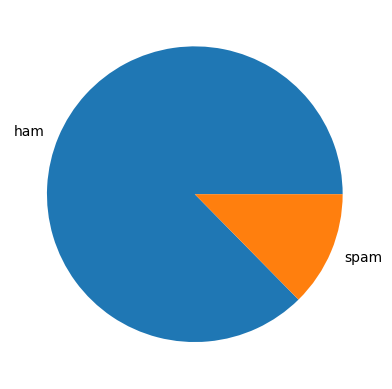

In [153]:
plt.pie(vc, labels=["ham", "spam"])
plt.show()

In [154]:
df['length']= df['text'].apply(len)
df.head()

,target,text,length
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [155]:
#number of words
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\new\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [156]:
df["word_count"]= df["text"].apply(lambda x: len(nltk.word_tokenize(x)))
df.head()

,target,text,length,word_count
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [158]:
df["sent_count"]= df["text"].apply(lambda x: len(nltk.sent_tokenize(x)))
df.head()

,target,text,length,word_count,sent_count
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [159]:
lst=['length', 'word_count', 'sent_count']
df[lst].describe()

,length,word_count,sent_count
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [160]:
df[df['target']==1][lst].describe()

,length,word_count,sent_count
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [161]:
df[df['target']==0][lst].describe()

,length,word_count,sent_count
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


<Axes: xlabel='word_count', ylabel='Count'>

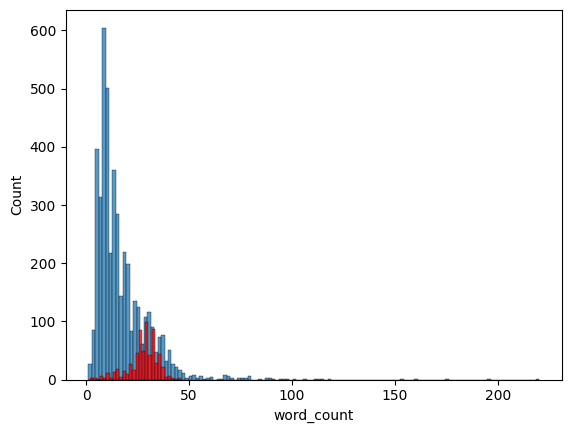

In [162]:
sns.histplot(df[df['target']==0]['word_count'])
sns.histplot(df[df['target']==1]['word_count'], color="red")

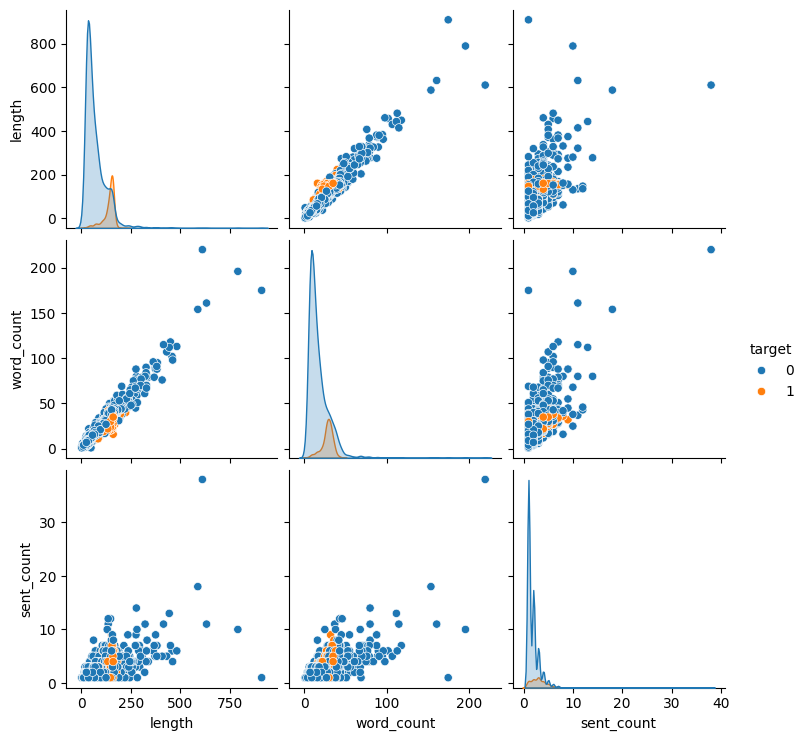

In [163]:
sns.pairplot(df, hue="target")

#3 Data processing
-> lower case
-> Tokenization
-> removing special characters
-> removing stop words and punctuation
-> stemming

In [164]:
def transform_text(text):
    text= text.lower()

    text= nltk.word_tokenize(text)

    ans=[]
    for ele in text:
        if(ele.isalnum()):
            ans.append(ele)

    text= ans.copy()
    ans.clear()

    for ele in text:
        if(ele not in stopwords.words('english')):
            ans.append(ele)

    text= ans.copy()
    ans.clear()

    for ele in text:
        ele= ps.stem(ele)
        ans.append(ele)
    
    return ' '.join(ans)

In [165]:
nltk.download("stopwords")
from nltk.corpus import stopwords
#stopwords.words('english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\new\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [166]:
from nltk.stem.porter import PorterStemmer
ps= PorterStemmer()
#ps.stem('seeing')

In [167]:
#transform_text("I love doing Machine Learning in 2025, do you like it?")

In [184]:
df['new text']= df['text'].apply(transform_text)
df.head()

,target,text,length,word_count,sent_count,new text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [185]:
#word cloud to count which words are appearing more in spam or ham
from wordcloud import WordCloud
wc= WordCloud(width=500, height=500, min_font_size=10, background_color="white")

In [186]:
spam= df[df['target']==1]['new text']
spam_str=' '.join(spam)
spam_wc= wc.generate(spam_str)

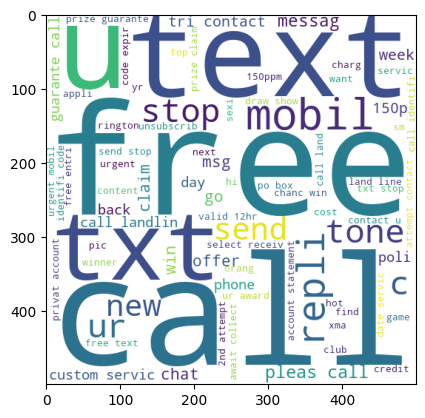

In [187]:
plt.imshow(spam_wc)

In [188]:
ham= df[df['target']==0]['new text']
ham_str=' '.join(ham)
ham_wc= wc.generate(ham_str)

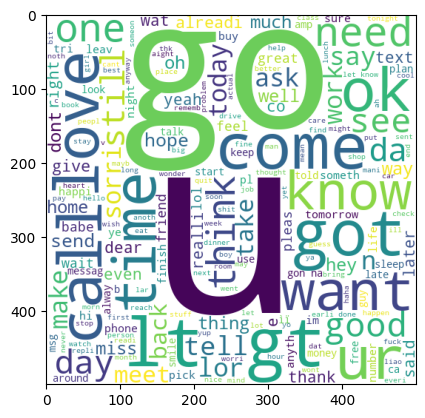

In [173]:
plt.imshow(ham_wc)

In [174]:
df.head()

,target,text,length,word_count,sent_count,new text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [175]:
#now our goal to find 30 top spam words and ham word
spam_list= spam.tolist()
spam_corpus= []
for item in spam_list:
    for word in item.split():
        spam_corpus.append(word)

len(spam_corpus)

9939

In [176]:
ham_list= ham.tolist()
ham_corpus= []
for item in ham_list:
    for word in item.split():
        ham_corpus.append(word)

len(ham_corpus)

35404

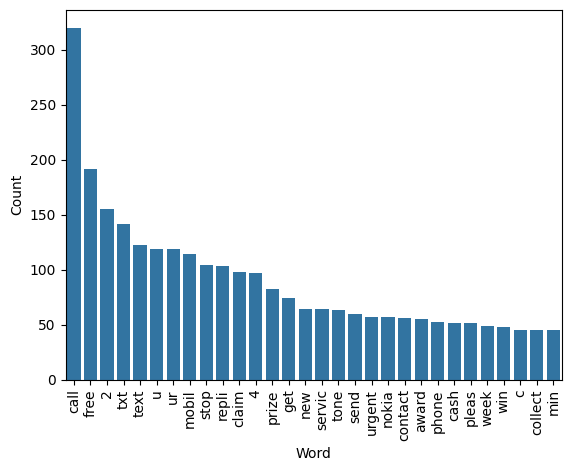

In [177]:
from collections import Counter
data = pd.DataFrame(Counter(spam_corpus).most_common(30), columns=['Word', 'Count'])

sns.barplot(x=data['Word'], y=data['Count'])
plt.xticks(rotation='vertical')
plt.show()

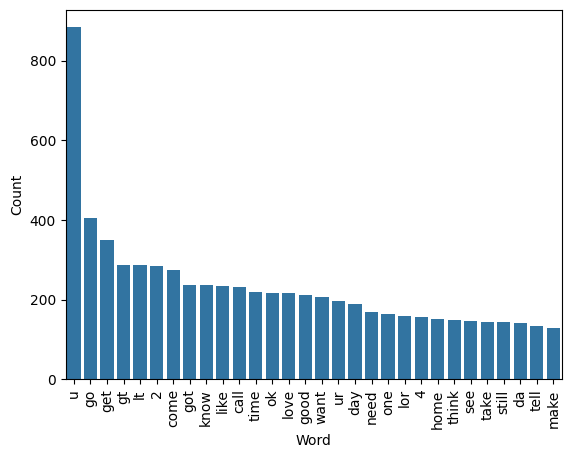

In [178]:
data = pd.DataFrame(Counter(ham_corpus).most_common(30), columns=['Word', 'Count'])

sns.barplot(x=data['Word'], y=data['Count'])
plt.xticks(rotation='vertical')
plt.show()

#4 MODEL BUILDING

In [189]:
#transformed text conversion to number -> vectors
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv= CountVectorizer()
tfidf= TfidfVectorizer(max_features=3000)

In [190]:
#sparse array to dense array
X= tfidf.fit_transform(df['new text']).toarray()
X.shape

(5169, 3000)

In [191]:
y= df['target'].values
y.shape

(5169,)

In [192]:
from sklearn.model_selection import train_test_split

In [193]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [194]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [195]:
gnb= GaussianNB()
mnb= MultinomialNB()
bnb= BernoulliNB()

In [196]:
gnb.fit(X_train, y_train)
y_pred1= gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8694390715667312
[[788 108]
 [ 27 111]]
0.5068493150684932


In [197]:
mnb.fit(X_train, y_train)
y_pred2= mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9709864603481625
[[896   0]
 [ 30 108]]
1.0


In [198]:
bnb.fit(X_train, y_train)
y_pred3= bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9835589941972921
[[895   1]
 [ 16 122]]
0.991869918699187


In [ ]:
while True:
    email = input("\nEnter a email (or type 'exit' to quit): ").strip()
    
    if email.lower() == 'exit':
        print("Exiting the program. Goodbye!")
        break
    
    else:
        # Preprocess the user input
        processed_email = transform_text(email)
        # Convert to TF-IDF vector
        email_tfidf = tfidf.transform([processed_email])
        # Predict
        prediction = mnb.predict(email_tfidf)
        # Output result
        print("The email is classified as:", "SPAM (1)" if prediction[0] == 1 else "NOT SPAM (0)")


Enter a email (or type 'exit' to quit):  hello how are you


The email is classified as: NOT SPAM (0)



Enter a email (or type 'exit' to quit):  free entry tickets


The email is classified as: SPAM (1)



Enter a email (or type 'exit' to quit):  you won one lakh rupees


The email is classified as: NOT SPAM (0)
